# Temporal Difference Learning: TD(0) Value Estimation

**Family:** Reinforcement learning | **Level:** Intermediate | **Dataset:** `FrozenLake-v1` | **Runs on:** CPU, about 2 minute(s)

Update value estimates after every step by bootstrapping.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- The TD error
- Bootstrapping versus Monte Carlo
- The effect of the step size
- Bias and variance of the two estimators

**Prerequisites:**

- Probability basics
- Markov decision processes

**Skills you will have afterwards:**

- Run several seeds
- Report learning curves with spread
- Compare with a baseline policy

## 2. Real-World Problem

**Context.** Waiting for the end of an episode is slow and noisy.

**The problem.** Estimate the value of a fixed policy on FrozenLake from experience, without a model.

**Why it matters.** TD learning is the base of Q-learning, SARSA and deep value methods.

**Why machine learning.** Values must be learned from sampled transitions.

**Why this algorithm.** Exact values from DP give a ground truth to measure the error of TD.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Learning to predict by the methods of temporal differences

- **Type:** foundational paper
- **Authors:** Sutton, R. S.
- **Year and venue:** 1988, Machine Learning 3(1):9-44
- **DOI or URL:** https://doi.org/10.1007/BF00115009
- **Verification:** Crossref 2026-11-17
- **Research objective:** Introduce temporal difference learning for prediction.
- **Methodology:** Update value estimates from the difference between successive predictions.
- **Dataset:** Random walk experiments.
- **Main findings:** TD methods learn faster than supervised updating on the random walk task.
- **Limitations:** Tabular and linear settings in the paper.

**Relationship to this notebook.** Sutton (1988) introduces TD methods and compares them with supervised prediction. We use a different task, the lake. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**TD(0) update.** $V(S_t) \leftarrow V(S_t) + \alpha\,\delta_t$ with $\delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t)$.

**Monte Carlo update.** $V(S_t) \leftarrow V(S_t) + \alpha\,(G_t - V(S_t))$.

**Bias and variance.** TD uses the current estimate as target, so it is biased early but has low variance. MC is unbiased but has high variance.

**Convergence.** For a fixed policy and decreasing step sizes TD(0) converges to $V^\pi$ (tabular).

## 5. Dataset Introduction

**FrozenLake-v1** 4 by 4 slippery. The policy is fixed to the optimal policy from dynamic programming. The true values come from exact policy evaluation with discount 1, so the error of the estimates can be measured exactly.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import display

from ml_lab.rl import tabular, deep
from ml_lab.evaluation import evaluate_policy
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "temporal_difference"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()
print("gymnasium", gym.__version__)

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
gymnasium 1.4.0


## 6. Exploratory Data Analysis

There is no dataset. We inspect the environment: observation and action spaces, rewards and a random policy baseline. 

In [2]:
P, nS, nA = tabular.transition_model("FrozenLake-v1", is_slippery=True)
_, optimal_policy, _ = tabular.value_iteration(P, nS, nA, 0.99)
true_values, _ = tabular.policy_evaluation(P, optimal_policy, nS, gamma=1.0)
print(np.round(true_values.reshape(4, 4), 3))

[[0.824 0.824 0.824 0.824]
 [0.824 0.    0.529 0.   ]
 [0.824 0.824 0.765 0.   ]
 [0.    0.882 0.941 0.   ]]


## 7. Data Preprocessing

The policy is fixed and the discount is 1 (the task ends). Error is root mean squared error over all non terminal states.

In [3]:
nonterminal = np.array([s for s in range(nS) if not all(done for a in range(nA) for _, _, _, done in P[s][a])])
def rmse(values):
    return float(np.sqrt(np.mean((values[nonterminal] - true_values[nonterminal]) ** 2)))
print("non terminal states:", len(nonterminal))

non terminal states: 11


## 8. Algorithm Implementation

### 8.1 Concept

After each step, move the value of the state you left a little towards reward plus the value of the state you reached.

### 8.2 Python implementation from scratch

The TD(0) function is in `ml_lab.rl.tabular`. We add an every visit Monte Carlo version here to compare.

In [4]:
print(inspect.getsource(tabular.td0_prediction))
def mc_prediction(policy, episodes, alpha=0.05, seed=0):
    env = gym.make("FrozenLake-v1", is_slippery=True)
    values = np.zeros(16); history = []
    env.reset(seed=seed)
    for _ in range(episodes):
        s, _ = env.reset(); states, done = [], False
        while not done:
            states.append(s)
            s, r, term, trunc, _ = env.step(int(policy[s])); done = term or trunc
        for st in states:
            values[st] += alpha * (r - values[st])      # return = final reward
        history.append(values.copy())
    return np.array(history)

def td0_prediction(env_id, policy, episodes, alpha=0.05, gamma=0.99, seed=0, **env_kwargs):
    """TD(0) value estimate of a fixed policy. Returns values after every episode."""
    env = gym.make(env_id, **env_kwargs)
    rng = np.random.default_rng(seed)
    values = np.zeros(env.observation_space.n)
    history = []
    env.reset(seed=seed)
    for _ in range(episodes):
        state, _ = env.reset()
        done = False
        while not done:
            nxt, reward, term, trunc, _ = env.step(int(policy[state]))
            values[state] += alpha * (reward + gamma * values[nxt] * (not term) - values[state])
            state, done = nxt, term or trunc
        history.append(values.copy())
    env.close()
    return values, np.array(history)



### 8.3 Library implementation

The algorithm is implemented in `src/ml_lab/rl` without an RL library. Gymnasium supplies only the environment.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `alpha` | Step size. |
| `gamma` | Discount, 1 here. |
| `episodes` | Training episodes. |

## 9. Model Training

Run TD(0) and Monte Carlo prediction with step sizes 0.01, 0.05 and 0.2 for 3000 episodes and 5 seeds. Track the error after every 100 episodes.

In [5]:
checkpoints = list(range(99, 3000, 100))
curves = {}
for method in ["TD(0)", "MC"]:
    for alpha in [0.01, 0.05, 0.2]:
        errs = []
        for seed in range(5):
            if method == "TD(0)":
                _, hist = tabular.td0_prediction("FrozenLake-v1", optimal_policy, 3000, alpha=alpha, gamma=1.0, seed=seed, is_slippery=True)
            else:
                hist = mc_prediction(optimal_policy, 3000, alpha=alpha, seed=seed)
            errs.append([rmse(hist[c]) for c in checkpoints])
        curves[(method, alpha)] = np.array(errs)
final = pd.DataFrame({f"{m} alpha={a}": [c[:, -1].mean(), c[:, -1].std(ddof=1)] for (m, a), c in curves.items()}, index=["rmse_mean", "rmse_std"]).T
display(final.round(4))

,rmse_mean,rmse_std
TD(0) alpha=0.01,0.1871,0.0054
TD(0) alpha=0.05,0.0281,0.0088
TD(0) alpha=0.2,0.0558,0.0214
MC alpha=0.01,0.2523,0.0520
MC alpha=0.05,0.2926,0.0912
MC alpha=0.2,0.4016,0.1302


## 10. Evaluation

Root mean squared error against the exact values after 3000 episodes, mean and spread over 5 seeds. The floor is the error of an all zero estimate.

In [6]:
floor = rmse(np.zeros(16))
best_key = min(curves, key=lambda k: curves[k][:, -1].mean())
METRICS = {"all_zero_rmse": floor, "best_final_rmse": float(curves[best_key][:, -1].mean()), "best_final_rmse_std": float(curves[best_key][:, -1].std(ddof=1)),
           "td_alpha_0.05_rmse": float(curves[("TD(0)", 0.05)][:, -1].mean()), "mc_alpha_0.05_rmse": float(curves[("MC", 0.05)][:, -1].mean())}
CONFIG = {"episodes": 3000, "alphas": [0.01, 0.05, 0.2], "best": f"{best_key[0]} alpha={best_key[1]}", "seeds": 5}
EXTRA = {"final_table": final.round(5).reset_index().to_dict("records")}
print("best setting:", best_key)

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="reinforcement_learning", algorithm="TD0", dataset="FrozenLake-v1",
                          task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

best setting: ('TD(0)', 0.05)
saved: /home/claude/open-python/experiments/results/temporal_difference.json


,metric
all_zero_rmse,0.8133
best_final_rmse,0.0281
best_final_rmse_std,0.0088
td_alpha_0.05_rmse,0.0281
mc_alpha_0.05_rmse,0.2926


## 11. Visualization

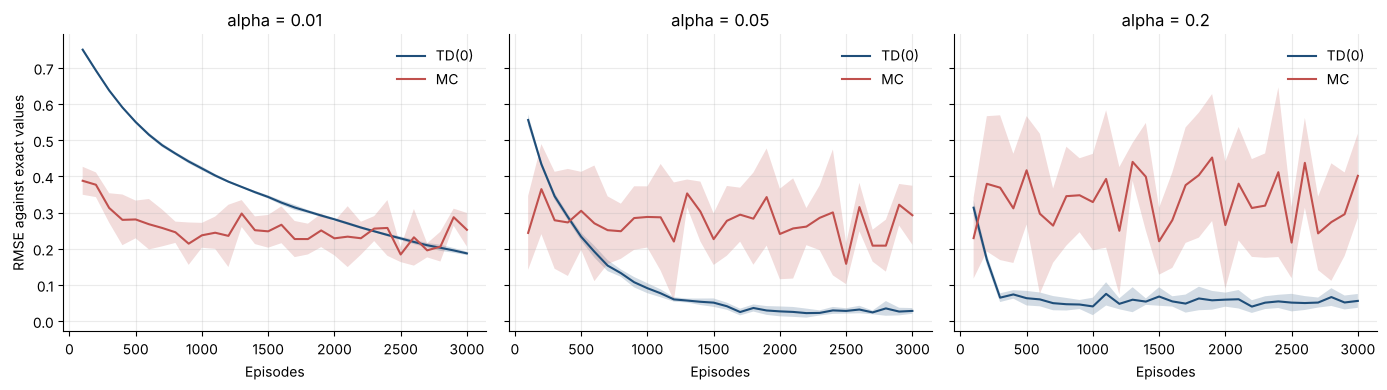

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, alpha in zip(axes, [0.01, 0.05, 0.2]):
    for method in ["TD(0)", "MC"]:
        c = curves[(method, alpha)]
        ax.plot(np.array(checkpoints) + 1, c.mean(axis=0), label=method)
        ax.fill_between(np.array(checkpoints) + 1, c.mean(axis=0) - c.std(axis=0), c.mean(axis=0) + c.std(axis=0), alpha=0.2)
    ax.set_title(f"alpha = {alpha}"); ax.set_xlabel("Episodes"); ax.legend()
axes[0].set_ylabel("RMSE against exact values")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "curves"); plt.show()

## 12. Interpretation

Compare the final values with the exact ones. Errors are larger in states far from the goal.

In [8]:
_, hist = tabular.td0_prediction("FrozenLake-v1", optimal_policy, 3000, alpha=0.05, gamma=1.0, seed=0, is_slippery=True)
display(pd.DataFrame({"exact": true_values, "TD(0) estimate": hist[-1]}).round(3).T)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
exact,0.824,0.824,0.824,0.824,0.824,0.0,0.529,0.0,0.824,0.824,0.765,0.0,0.0,0.882,0.941,0.0
TD(0) estimate,0.815,0.825,0.832,0.837,0.816,0.0,0.575,0.0,0.819,0.829,0.794,0.0,0.0,0.905,0.956,0.0


## 13. Experiments and Challenges

### Experiment 1: Step size and noise

A larger step size learns faster but keeps more noise. Compare the spread of the last 10 checkpoints.

In [9]:
for (m, a), c in curves.items():
    print(f"{m} alpha={a}: mean of last 10 checkpoints {c[:, -10:].mean():.4f}, std within run {c[:, -10:].std(axis=1).mean():.4f}")

TD(0) alpha=0.01: mean of last 10 checkpoints 0.2257, std within run 0.0264
TD(0) alpha=0.05: mean of last 10 checkpoints 0.0273, std within run 0.0109
TD(0) alpha=0.2: mean of last 10 checkpoints 0.0532, std within run 0.0205
MC alpha=0.01: mean of last 10 checkpoints 0.2332, std within run 0.0492
MC alpha=0.05: mean of last 10 checkpoints 0.2608, std within run 0.0948
MC alpha=0.2: mean of last 10 checkpoints 0.3290, std within run 0.1507


### Experiment 2: Speed in the first 200 episodes

Error after 100 and 300 episodes.

In [10]:
for (m, a), c in curves.items():
    print(f"{m} alpha={a}: rmse after 100 episodes {c[:, 0].mean():.3f}, after 300 episodes {c[:, 2].mean():.3f}")

TD(0) alpha=0.01: rmse after 100 episodes 0.750, after 300 episodes 0.638
TD(0) alpha=0.05: rmse after 100 episodes 0.556, after 300 episodes 0.345
TD(0) alpha=0.2: rmse after 100 episodes 0.313, after 300 episodes 0.065
MC alpha=0.01: rmse after 100 episodes 0.388, after 300 episodes 0.313
MC alpha=0.05: rmse after 100 episodes 0.244, after 300 episodes 0.279
MC alpha=0.2: rmse after 100 episodes 0.229, after 300 episodes 0.369


### Experiment 3: Wrong policy

Evaluate a random policy with the same code. The values differ from the optimal policy values.

In [11]:
random_policy = np.random.default_rng(0).integers(0, 4, nS)
v_true_random, _ = tabular.policy_evaluation(P, random_policy, nS, gamma=1.0)
print("start state value, optimal policy:", round(float(true_values[0]), 3), "| random fixed policy:", round(float(v_true_random[0]), 4))

start state value, optimal policy: 0.824 | random fixed policy: 0.0271


### Exercises for learners

1. Repeat with a different set of seeds and report the spread.
2. Change the discount factor and describe what happens to the learned behaviour.
3. Change one hyperparameter by a factor of 10 and compare learning curves.

## 14. Research Discussion

Sutton (1988) argues that TD methods use experience more efficiently than methods that wait for the outcome. Our curves test this on one small task where the reward is sparse, so the comparison is limited to that case.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Try TD(lambda) and eligibility traces, and decaying step sizes.

**Research limitations.** One dataset and one seed for the headline numbers. Few seeds (see the notebook), small environments, and no hyperparameter search beyond the experiments shown.

## 15. Summary and Further Reading

**Key takeaways**

- TD bootstraps and updates every step.
- Step size trades speed for noise.
- Exact values allow exact error measurement.

**Use cases.** Prediction, base of control methods.

**Limitations.** Fixed policy here, tabular only.

**Recommended next notebook.** SARSA.

**Further reading.** See `references.md` in this folder.